# Adaptive spatial weighting: lambda-cap study

## 1. Goal and experimental design

We examine how limiting SC-PaCMAP's adaptive spatial weighting changes the balance between **spatial contiguity** and **multivariate delineation** across CMiO, North Batten, and synthetic repeated facies. The aim is to show the practical trade-off obtained by the data-derived rule without choosing a separate cap for each dataset.

The experiment sweeps ten equally spaced values of `max_target_share` from 0 to 1. This parameter caps both lambda inside the share calculation and the resulting Phase-3 spatial-attraction share; it does **not** set lambda to a fixed value. At cap 1, the adaptive rule operates without extra clipping. The automatic lambda is calculated from the data, while the realized target share also depends on the attraction balance.

**Controlled settings:** algorithm seed **42**, K-means seed **42** with 20 initializations, embedding neighborhood size **10**, and 450 optimization iterations. Each full dataset is held fixed. The synthetic population also uses data seed **42**. The cluster count is derived from each dataset's label classes: CMiO **7**, North Batten **15**, Synthetic **4**. Labels select the evaluation cluster count only; they do not enter the embedding or lambda calculation.

This is a **single-seed cap-sensitivity study**. It can illustrate dataset-dependent adaptation and the observed trade-off; it does not establish seed robustness or an optimal balance. A plateau can occur simply because the cap is no longer active.

All experiment and plotting code is contained here, using the existing SC-PaCMAP implementation. Results stay in notebook memory and the figure appears directly below; no result files or images are exported.

In [1]:
from __future__ import annotations
import os, sys
from pathlib import Path
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import numba
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
numba.set_num_threads(1)
set_matplotlib_formats('png')

def find_root():
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'sc-pacmap-reproducibility'):
            if (candidate / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file():
                return candidate
    raise FileNotFoundError('Run this notebook from within the SC-PaCMAP project.')

ROOT = find_root()
sys.path.insert(0, str(ROOT / 'code' / 'sc_pacmap'))
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_sc_pacmap
SEED = 42
N_NEIGHBORS = 10
LAMBDA_CAPS = np.linspace(0., 1., 10)
SETTINGS = PaCMAPSettings(random_state=SEED, n_components=2, n_neighbors=N_NEIGHBORS,
                         mn_ratio=.5, fp_ratio=2., learning_rate=1.,
                         num_iters=(100, 100, 250), knn_backend='faiss', verbose=False)
datasets = {}

def prepare_dataset(data, feature_columns, coordinate_columns, label_column, expected_k):
    assert not data[feature_columns + coordinate_columns + [label_column]].isna().any().any()
    features = StandardScaler().fit_transform(data[feature_columns].to_numpy(np.float64)).astype(np.float32)
    coords = data[coordinate_columns].to_numpy(np.float64)
    truth = data[label_column].to_numpy()
    k = int(pd.Series(truth).nunique())
    assert k == expected_k, f'Unexpected label-class count: {k}'
    assert np.isfinite(features).all() and np.isfinite(coords).all()
    # Match the geographic-neighbor evaluation in New_Notebooks.
    neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
    tss = float(np.sum((features - features.mean(0, keepdims=True)) ** 2))
    assert tss > 0
    return dict(features=features, coords=coords, K=k, neighbors=neighbors, tss=tss)

## 2. Load and prepare the three datasets

### 2.1 CMiO
Use the same 35 geochemical features and full processed population as the results notebook. Coordinates are supplied separately to the spatial graph; features are standardized.

In [2]:
FEATURES = ['Y_PPM', 'V_PPM', 'LA_PPM', 'U_PPM', 'SR_PPM', 'SN_PPM', 'RB_PPM', 'TH_PPM', 'CS_PPM', 'CE_PPM', 'NB_PPM', 'GA_PPM', 'W_PPM', 'HF_PPM', 'TA_PPM', 'ZR_PPM', 'CR_PPM', 'PR_PPM', 'ND_PPM', 'ER_PPM', 'EU_PPM', 'SM_PPM', 'YB_PPM', 'TB_PPM', 'HO_PPM', 'GD_PPM', 'DY_PPM', 'LU_PPM', 'BA_PPM', 'SIO2_WT_PERCENT', 'TIO2_WT_PERCENT', 'NA2O_WT_PERCENT', 'K2O_WT_PERCENT', 'AL2O3_WT_PERCENT', 'TM_PPM']
cmio = pd.read_csv(ROOT / 'data' / 'processed' / 'cmio_sc_pacmap_ready.csv')
datasets['CMiO'] = prepare_dataset(cmio, FEATURES, ['x', 'y', 'z'], 'label_id', 7)

### 2.2 North Batten
Use the processed drillhole population and the same geochemical columns ending in `_PPM` or `_PCT`. The label classes determine the dataset-specific K.

In [3]:
north_batten = pd.read_csv(ROOT / 'data' / 'processed' / 'north_batten_sc_pacmap_ready.csv')
nb_features = [c for c in north_batten.columns if c.endswith(('_PPM', '_PCT'))]
datasets['North Batten'] = prepare_dataset(north_batten, nb_features, ['x', 'y', 'z'], 'label_id', 15)

### 2.3 Synthetic repeated facies
The original benchmark's data generator and constants are included below so this notebook requires no helper script or execution of another notebook. Seed 42 reproduces the same 1,024 samples, 50 features, and four facies.

In [4]:
SEED = 42

GRID_SIDE = 32

TILES_PER_SIDE = 4

TILE_SIDE = GRID_SIDE // TILES_PER_SIDE

N_SAMPLES = GRID_SIDE**2

N_FEATURES = 50

KNOWN_CLASS_COUNT = 4

XY_COLUMNS = ["x_m", "y_m"]

LABEL_COLUMN = "truth_facies"

SPATIAL_FEATURES = [f"spatial_{index:02d}" for index in range(1, 11)]

CONFOUNDER_FEATURES = [f"confounder_{index:02d}" for index in range(1, 21)]

NOISE_FEATURES = [f"noise_{index:02d}" for index in range(1, 21)]

FEATURE_COLUMNS = SPATIAL_FEATURES + CONFOUNDER_FEATURES + NOISE_FEATURES

METADATA_COLUMNS = [
    "sample_id",
    *XY_COLUMNS,
    LABEL_COLUMN,
    "facies_id",
    "patch_id",
]

EXPECTED_LABELS = {
    0: "Facies A",
    1: "Facies B",
    2: "Facies C",
    3: "Facies D",
}

def make_synthetic_repeated_facies(
    random_state: int = SEED,
) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    """Create the repeated-facies benchmark and its plotting-only latent values."""
    # 1. Use one local random generator so the complete dataset is reproducible.
    rng = np.random.default_rng(random_state)

    # 2. Create a 32 x 32 sampling grid, then add about 1 m of coordinate jitter.
    #    Adjacent nominal samples remain 25 m apart, but the layout is not perfectly regular.
    grid_axis = np.arange(GRID_SIDE)
    x_grid, y_grid = np.meshgrid(grid_axis, grid_axis)
    x_index = x_grid.ravel().astype(np.int64)
    y_index = y_grid.ravel().astype(np.int64)
    coordinate_indices = np.column_stack([x_index, y_index]).astype(np.float64)
    coordinate_jitter = rng.normal(0.0, 0.04, size=coordinate_indices.shape)
    coordinates = 25.0 * (coordinate_indices + coordinate_jitter)

    # 3. Divide the grid into sixteen 8 x 8 physical patches.
    tile_x = x_index // TILE_SIDE
    tile_y = y_index // TILE_SIDE
    patch_id = tile_y * TILES_PER_SIDE + tile_x

    # Apply a Latin-square rule. Each facies occurs in four disconnected patches.
    facies_id = (tile_x + tile_y) % KNOWN_CLASS_COUNT

    # 4. Give every facies a balanced three-value signature.
    #    Any two facies differ in exactly two of the three signature values.
    facies_prototype = np.array(
        [
            [-1.0, -1.0, -1.0],  # Facies A
            [-1.0, +1.0, +1.0],  # Facies B
            [+1.0, -1.0, +1.0],  # Facies C
            [+1.0, +1.0, -1.0],  # Facies D
        ],
        dtype=np.float64,
    )

    # Build ten answer-bearing features from the three-value signatures.
    # Features cycle through signature positions 0, 1, 2 while their noise increases.
    spatial_noise_sigma = np.linspace(0.15, 0.95, 10)
    spatial_columns = []
    for feature_index, noise_sigma in enumerate(spatial_noise_sigma):
        prototype_position = feature_index % facies_prototype.shape[1]
        facies_signal = facies_prototype[facies_id, prototype_position]
        measurement_noise = noise_sigma * rng.normal(size=N_SAMPLES)
        spatial_columns.append(facies_signal + measurement_noise)
    spatial_block = np.column_stack(spatial_columns)

    # 5. Draw nuisance values independently for each sample. They have no intended
    #    relationship with facies or location, but their nonlinear structure is strong.
    nuisance_theta = rng.uniform(-np.pi, np.pi, size=N_SAMPLES)
    nuisance_q = rng.normal(size=N_SAMPLES)
    nuisance_radius = 1.0 + 0.18 * rng.normal(size=N_SAMPLES)

    # Name repeated transformations so the twenty confounders are easier to read.
    cos_theta = np.cos(nuisance_theta)
    sin_theta = np.sin(nuisance_theta)
    tanh_q = np.tanh(nuisance_q)
    centered_q_squared = nuisance_q**2 - 1.0

    confounder_basis = np.column_stack(
        [
            # A noisy circular manifold and its second and third harmonics.
            nuisance_radius * cos_theta,
            nuisance_radius * sin_theta,
            np.cos(2.0 * nuisance_theta),
            np.sin(2.0 * nuisance_theta),
            np.cos(3.0 * nuisance_theta),
            np.sin(3.0 * nuisance_theta),
            # Saturating, polynomial, and periodic transforms of q.
            tanh_q,
            centered_q_squared,
            np.sin(1.5 * nuisance_q),
            np.cos(1.5 * nuisance_q),
            # Additive mixtures of the angle and q structures.
            cos_theta + 0.55 * tanh_q,
            sin_theta - 0.55 * tanh_q,
            np.cos(2.0 * nuisance_theta) + 0.35 * centered_q_squared,
            np.sin(2.0 * nuisance_theta) - 0.35 * centered_q_squared,
            # Multiplicative interactions between the angle and q structures.
            tanh_q * cos_theta,
            tanh_q * sin_theta,
            centered_q_squared * cos_theta,
            centered_q_squared * sin_theta,
            # Two final nonlinear combinations.
            np.sin(nuisance_theta + nuisance_q),
            np.cos(nuisance_theta - nuisance_q),
        ]
    )
    confounder_noise = rng.normal(0.0, 0.12, size=confounder_basis.shape)
    confounder_block = confounder_basis + confounder_noise

    # 6. Add twenty completely independent distractor features.
    independent_block = rng.normal(size=(N_SAMPLES, 20))

    # 7. Join the three feature blocks in their documented 10 + 20 + 20 order.
    feature_matrix = np.column_stack(
        [spatial_block, confounder_block, independent_block]
    )
    assert feature_matrix.shape == (N_SAMPLES, N_FEATURES)

    # Keep labels and locations as metadata; they are not part of FEATURE_COLUMNS.
    metadata = pd.DataFrame(
        {
            "sample_id": [f"S{index:04d}" for index in range(N_SAMPLES)],
            "x_m": coordinates[:, 0],
            "y_m": coordinates[:, 1],
            LABEL_COLUMN: [EXPECTED_LABELS[value] for value in facies_id],
            "facies_id": facies_id,
            "patch_id": patch_id,
        }
    )
    feature_data = pd.DataFrame(feature_matrix, columns=FEATURE_COLUMNS)
    generated = pd.concat([metadata, feature_data], axis=1)

    # Return latent values only for diagnostics and plotting.
    latent = {
        "nuisance_theta": nuisance_theta,
        "spatial_noise_sigma": spatial_noise_sigma,
    }
    return generated, latent

synthetic, _ = make_synthetic_repeated_facies(random_state=SEED)
assert synthetic.shape == (1024, 56)
datasets['Synthetic'] = prepare_dataset(synthetic, FEATURE_COLUMNS, XY_COLUMNS, 'facies_id', 4)
display(pd.DataFrame([{'Dataset': name, 'Samples': len(d['features']), 'Features': d['features'].shape[1], 'K (label classes)': d['K'], 'Seed': SEED} for name, d in datasets.items()]).set_index('Dataset'))

,Samples,Features,K (label classes),Seed
Dataset,,,,
CMiO,1551,35,7,42
North Batten,3222,46,15,42
Synthetic,1024,50,4,42


## 3. Evaluation: what is a useful trade-off?

Each embedding is clustered at its dataset's own K, with fixed K-means settings. Both scores are expressed as percentages, with higher values better:

- **Spatial contiguity:** $100[1-(H/N)/\log K]$, where $H/N$ is the mean cluster-label entropy over ten geographic neighbors.
- **Multivariate delineation:** $100[1-\mathrm{WCSS}/\mathrm{TSS}]$, measured in the standardized original feature space.

We compare the unrestricted adaptive result (cap 1) with the zero-cap reference and report the change in **percentage points** for each score. A spatial gain alongside a delineation loss represents an explicit trade-off, not simultaneous improvement. The two scores measure different properties; equal numeric values do not define an optimum.

In [5]:
def evaluate_embedding(embedding, dataset):
    features, k = dataset['features'], dataset['K']
    labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED).fit_predict(embedding)
    entropies = []
    for neighbors in dataset['neighbors']:
        counts = np.bincount(labels[neighbors], minlength=k)
        probabilities = counts[counts > 0] / len(neighbors)
        entropies.append(-np.sum(probabilities * np.log(probabilities)))
    mean_entropy = float(np.mean(entropies))
    centers = np.vstack([features[labels == j].mean(0) for j in range(k)])
    within_ss = float(np.sum((features - centers[labels]) ** 2))
    return {'spatial': 100 * (1 - mean_entropy / np.log(k)),
            'multivariate': 100 * (1 - within_ss / dataset['tss'])}

## 4. Run the capped sweep at seed 42

Run SC-PaCMAP for each of the ten caps on each dataset: **30 fits in total**. Record automatic lambda and realized target share alongside both evaluation scores. These diagnostics distinguish the inferred lambda from the cap and the actual attraction share.

In [6]:
rows = []
for name, dataset in datasets.items():
    with threadpool_limits(limits=1):
        for cap in LAMBDA_CAPS:
            result, diagnostics = run_sc_pacmap(
                dataset['features'], dataset['coords'], SETTINGS,
                config=SCPaCMAPConfig(max_target_share=float(cap)))
            rows.append({'dataset': name, 'K': dataset['K'], 'seed': SEED,
                         'lambda_cap': float(cap),
                         'automatic_lambda': diagnostics.spatial_strength_lambda,
                         'target_share': diagnostics.automatic_target_share,
                         **evaluate_embedding(result.embedding, dataset)})
    print(f'{name}: all {len(LAMBDA_CAPS)} caps complete (K={dataset["K"]}, seed={SEED})', flush=True)
lambda_results = pd.DataFrame(rows)
assert len(lambda_results) == 30
assert not lambda_results.duplicated(['dataset', 'lambda_cap']).any()
assert np.isfinite(lambda_results.select_dtypes(include='number')).all().all()
assert lambda_results.groupby('dataset').size().eq(10).all()

CMiO: all 10 caps complete (K=7, seed=42)


North Batten: all 10 caps complete (K=15, seed=42)


Synthetic: all 10 caps complete (K=4, seed=42)


## 5. Combined publication figure

Three square panels share the same 0?100% scale. Blue circles show spatial contiguity; orange squares show multivariate delineation. The dashed vertical line marks the data-derived automatic lambda **as a reference**, while the rightmost points (cap 1) are the unrestricted adaptive results. There are no uncertainty bands because only one seed is evaluated.

The figure uses serif typography, distinct markers, and a shared legend at approximately 180 mm full-paper width. The inline PNG is rendered at **600 dpi**: copy or save the image directly from this notebook output. Nothing is exported automatically.

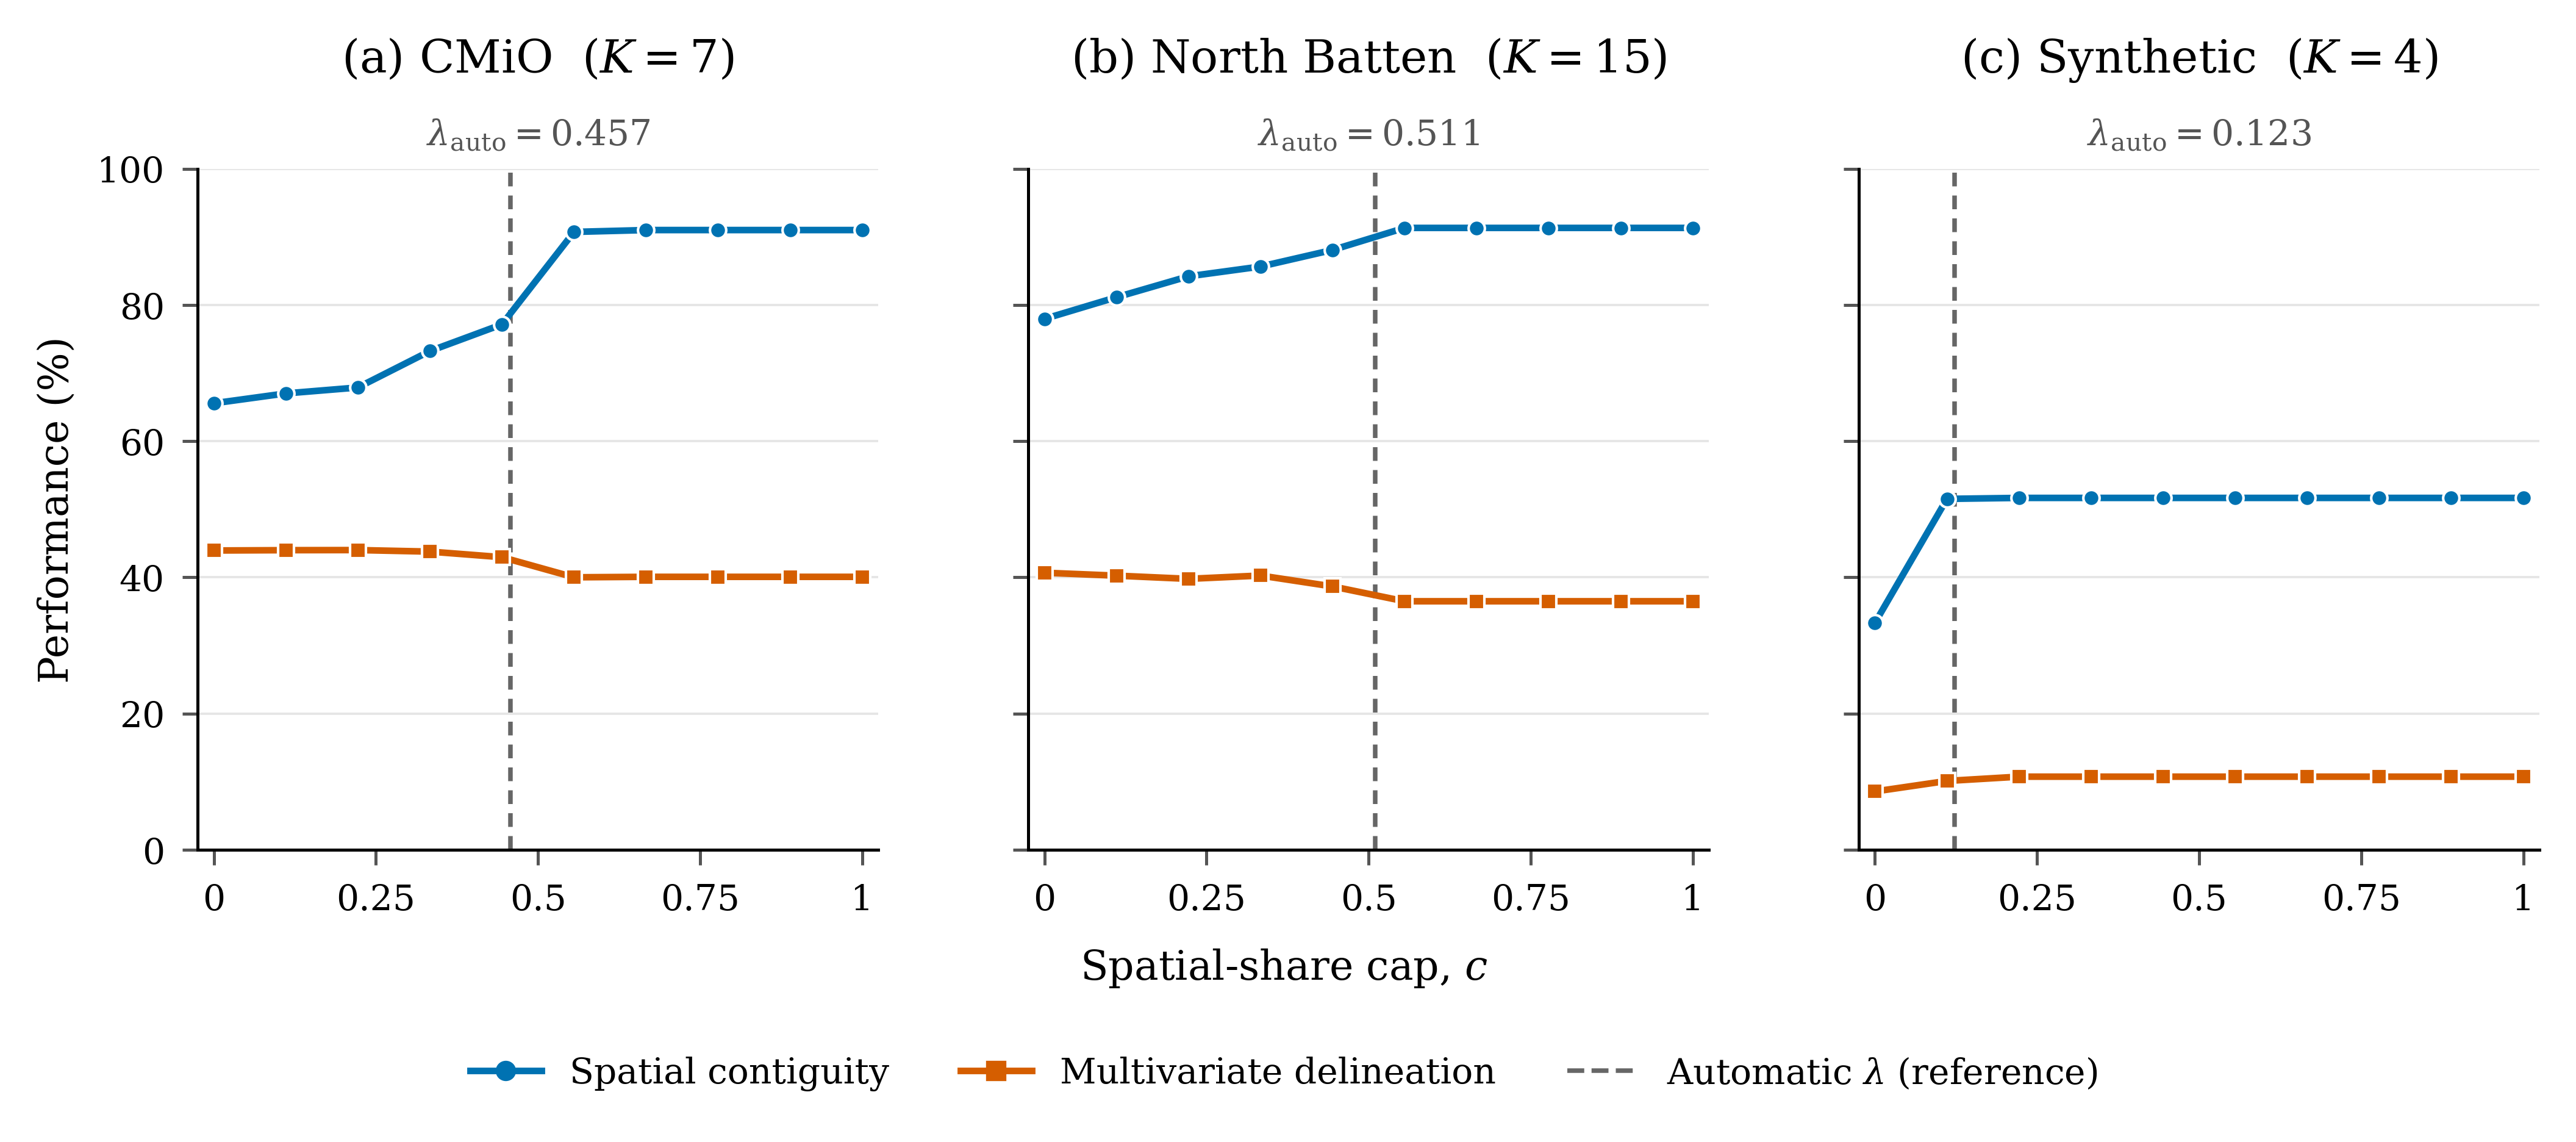

In [7]:
paper_style = {
    'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'mathtext.fontset': 'dejavuserif', 'font.size': 8,
    'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7,
    'ytick.labelsize': 7, 'axes.linewidth': .6, 'axes.grid': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 600, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
}
with plt.rc_context(paper_style):
    fig, axes = plt.subplots(1, 3, figsize=(7.1, 3.05), sharex=True, sharey=True)
    fig.subplots_adjust(left=.075, right=.99, bottom=.25, top=.86, wspace=.16)
    for index, (ax, name) in enumerate(zip(axes, datasets)):
        part = lambda_results.loc[lambda_results.dataset == name].sort_values('lambda_cap')
        for metric, color, marker in [('spatial', '#0072B2', 'o'),
                                       ('multivariate', '#D55E00', 's')]:
            ax.plot(part.lambda_cap, part[metric], color=color, marker=marker,
                    markersize=3.2, markeredgecolor='white', markeredgewidth=.5, linewidth=1.3)
        automatic = float(part.automatic_lambda.iloc[0])
        ax.axvline(automatic, color='#666666', ls=(0, (3, 2)), lw=.9, zorder=1)
        ax.set_title(f'({chr(97 + index)}) {name}  ($K={int(part.K.iloc[0])}$)', pad=19)
        ax.text(.5, 1.035, rf'$\lambda_{{\mathrm{{auto}}}}={automatic:.3f}$',
                transform=ax.transAxes, ha='center', fontsize=7, color='#555555')
        ax.set(xlim=(-.025, 1.025), ylim=(0, 100), xticks=[0, .25, .5, .75, 1],
               yticks=np.arange(0, 101, 20))
        ax.set_xticklabels(['0', '0.25', '0.5', '0.75', '1'])
        ax.set_box_aspect(1)
        ax.grid(axis='y', color='#E5E5E5', linewidth=.45)
        ax.tick_params(length=3, width=.6, color='#555555')
    axes[0].set_ylabel('Performance (%)')
    fig.supxlabel(r'Spatial-share cap, $c$', y=.125, fontsize=8)
    handles = [Line2D([], [], color='#0072B2', marker='o', markersize=3, lw=1.3,
                      label='Spatial contiguity'),
               Line2D([], [], color='#D55E00', marker='s', markersize=3, lw=1.3,
                      label='Multivariate delineation'),
               Line2D([], [], color='#666666', ls='--', lw=.9, label=r'Automatic $\lambda$ (reference)')]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .005),
               ncol=3, frameon=False, fontsize=7, handlelength=2)
    display(fig)
    plt.close(fig)

**Suggested figure caption.** Sensitivity of SC-PaCMAP to the spatial-share cap on (a) CMiO, (b) North Batten, and (c) synthetic repeated facies. Ten caps from 0 to 1 are evaluated with algorithm and K-means seeds fixed at 42, using each dataset's label-class count K. Higher scores indicate greater spatial contiguity or multivariate delineation. Dashed lines mark the data-derived automatic lambda for reference; cap 1 permits the unrestricted adaptive rule. Results illustrate a single-seed trade-off and do not represent uncertainty estimates.

## 6. Interpretation of the adaptive result

The table compares cap 0 with cap 1 and reports the inferred lambda, actual target share, and score changes. Dataset-dependent lambda values demonstrate that the inferred strength responds to the input data. Whether its resulting balance is useful must be judged from **both** score changes. Saturation of the cap sweep demonstrates insensitivity to further cap relaxation, not proof that an optimum was found.

In [8]:
comparison = []
for name in datasets:
    part = lambda_results.loc[lambda_results.dataset == name].sort_values('lambda_cap')
    zero, adaptive = part.iloc[0], part.iloc[-1]
    comparison.append({'Dataset': name, 'K': int(adaptive.K),
                       'Automatic lambda': adaptive.automatic_lambda,
                       'Adaptive target share': adaptive.target_share,
                       'Spatial: cap 0 (%)': zero.spatial,
                       'Spatial: adaptive (%)': adaptive.spatial,
                       'Spatial change (pp)': adaptive.spatial - zero.spatial,
                       'Multivariate: cap 0 (%)': zero.multivariate,
                       'Multivariate: adaptive (%)': adaptive.multivariate,
                       'Multivariate change (pp)': adaptive.multivariate - zero.multivariate})
adaptive_comparison = pd.DataFrame(comparison).set_index('Dataset')
display(adaptive_comparison.round(3))

,K,Automatic lambda,Adaptive target share,Spatial: cap 0 (%),Spatial: adaptive (%),Spatial change (pp),Multivariate: cap 0 (%),Multivariate: adaptive (%),Multivariate change (pp)
Dataset,,,,,,,,,
CMiO,7,0.457,0.561,65.551,90.989,25.438,43.932,40.065,-3.867
North Batten,15,0.511,0.546,77.942,91.304,13.362,40.670,36.478,-4.192
Synthetic,4,0.123,0.157,33.299,51.655,18.356,8.551,10.722,2.171
